In [1]:
from google.colab import drive
import os
import pandas as pd

# Connect Google Drive
drive.mount('/content/drive')

# Create project folders
PROJECT_DIR = "/content/drive/MyDrive/AI_YouTube_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "output")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project setup complete!")
print("Project folder:", PROJECT_DIR)
print("Data folder:", DATA_DIR)
print("Output folder:", OUTPUT_DIR)


Mounted at /content/drive
Project setup complete!
Project folder: /content/drive/MyDrive/AI_YouTube_Project
Data folder: /content/drive/MyDrive/AI_YouTube_Project/data
Output folder: /content/drive/MyDrive/AI_YouTube_Project/output


In [2]:
%pip -q install google-api-python-client youtube-transcript-api pandas scikit-learn matplotlib openpyxl

print("All required libraries are installed.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 485.2/485.2 kB 2.1 MB/s eta 0:00:00
All required libraries are installed.


In [3]:

from google.colab import userdata
from googleapiclient.discovery import build
import pandas as pd
import os

# Read the API key from Colab Secrets
API_KEY = userdata.get("YoutubeApi")

# Connect to YouTube Data API v3
youtube = build("youtube", "v3", developerKey=API_KEY)

# Search for AI-related videos
search_response = youtube.search().list(
    part="snippet",
    q="artificial intelligence",
    type="video",
    maxResults=30,
    order="relevance"
).execute()

# Collect video IDs and basic information
videos = []

for item in search_response.get("items", []):
    snippet = item["snippet"]

    videos.append({
        "video_id": item["id"]["videoId"],
        "title": snippet["title"],
        "channel": snippet["channelTitle"],
        "published_at": snippet["publishedAt"],
        "description": snippet["description"]
    })

df = pd.DataFrame(videos)

# Fetch video statistics
video_ids = df["video_id"].tolist()

stats_response = youtube.videos().list(
    part="statistics,contentDetails",
    id=",".join(video_ids)
).execute()

stats = {}

for item in stats_response.get("items", []):
    stats[item["id"]] = {
        "views": int(item["statistics"].get("viewCount", 0)),
        "likes": int(item["statistics"].get("likeCount", 0)),
        "comments_count": int(
            item["statistics"].get("commentCount", 0)
        ),
        "duration": item["contentDetails"]["duration"]
    }

df["views"] = df["video_id"].map(
    lambda x: stats.get(x, {}).get("views", 0)
)
df["likes"] = df["video_id"].map(
    lambda x: stats.get(x, {}).get("likes", 0)
)
df["comments_count"] = df["video_id"].map(
    lambda x: stats.get(x, {}).get("comments_count", 0)
)
df["duration"] = df["video_id"].map(
    lambda x: stats.get(x, {}).get("duration", "")
)

# Save to your Google Drive project folder
DATA_DIR = "/content/drive/MyDrive/AI_YouTube_Project/data"
os.makedirs(DATA_DIR, exist_ok=True)

output_path = os.path.join(DATA_DIR, "youtube_videos.csv")
df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Videos collected:", len(df))
print("Saved to:", output_path)

display(df.head())


Videos collected: 30
Saved to: /content/drive/MyDrive/AI_YouTube_Project/data/youtube_videos.csv


,video_id,title,channel,published_at,description,views,likes,comments_count,duration
0,-Q4Uzw8SG-0,How books are being scanned and destroyed to t...,FRANCE 24 English,2026-10-16T09:32:31Z,"To train artificial intelligence models, milli...",181127,1050,413,PT4M13S
1,XNbE8Awc8Z8,How Artificial Intelligence Is Reshaping the W...,World Governments Summit,2026-10-15T16:30:13Z,Is artificial intelligence the biggest technol...,15153,122,22,PT7M42S
2,_19pRsZRiz4,A.I. Artificial Intelligence - Official® Trail...,TrailersPlaygroundHD,2013-05-22T03:40:33Z,"Release Date: June 29, 2001 It's the mid-21st ...",3272028,15032,0,PT1M10S
3,F-pMp8AaXvw,artificial intelligence(SLOWED),JG,2025-05-25T18:09:46Z,,6637217,50847,670,PT2M35S
4,mUw27wG7uFA,AI Simplified: 6 Concepts You Need to Know Abo...,IBM Technology,2026-09-06T11:00:09Z,Learn more about Artificial Intelligence (AI) ...,998458,8854,479,PT8M49S


In [4]:

from googleapiclient.errors import HttpError
import time

comments = []

for video_id in df["video_id"]:
    try:
        response = youtube.commentThreads().list(
            part="snippet",
            videoId=video_id,
            maxResults=100,
            textFormat="plainText",
            order="relevance"
        ).execute()

        for item in response.get("items", []):
            comment = item["snippet"]["topLevelComment"]["snippet"]

            comments.append({
                "video_id": video_id,
                "comment": comment.get("textDisplay", ""),
                "like_count": comment.get("likeCount", 0),
                "published_at": comment.get("publishedAt", "")
            })

    except HttpError as e:
        # Some videos disable comments or restrict access
        print(f"Skipping video {video_id}: {e.resp.status}")

comments_df = pd.DataFrame(comments)

comments_path = os.path.join(DATA_DIR, "youtube_comments.csv")
comments_df.to_csv(
    comments_path, index=False, encoding="utf-8-sig"
)

print("Comments collected:", len(comments_df))
print("Saved to:", comments_path)

display(comments_df.head())


Skipping video _19pRsZRiz4: 403


Skipping video JcXKbUIebrU: 403


Skipping video qD-o2lDQwa8: 403


Skipping video 9gpvus-fPyo: 403
Comments collected: 2299
Saved to: /content/drive/MyDrive/AI_YouTube_Project/data/youtube_comments.csv


,video_id,comment,like_count,published_at
0,-Q4Uzw8SG-0,"This is, more than anything, pure evil.",119,2026-10-16T12:38:08Z
1,-Q4Uzw8SG-0,This should be illegal. They'll gate keep the ...,117,2026-10-16T12:07:26Z
2,-Q4Uzw8SG-0,I dont have a lot of money but I have started ...,89,2026-10-16T09:57:54Z
3,-Q4Uzw8SG-0,"so that no one can study on their own anymore,...",19,2026-10-17T12:08:33Z
4,-Q4Uzw8SG-0,"Scanning fine, destroying? That’s the part tha...",14,2026-10-17T11:15:28Z


In [5]:
import os
import re
import pandas as pd
from IPython.display import display

# Load datasets from Google Drive
videos_df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_videos.csv")
)

comments_df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments.csv")
)

# Function to clean text
def clean_text(text):
    if pd.isna(text):
        return ""

    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Clean video text
videos_df["clean_title"] = videos_df["title"].apply(clean_text)
videos_df["clean_description"] = videos_df["description"].apply(clean_text)

# Clean comments
comments_df["clean_comment"] = comments_df["comment"].apply(clean_text)

# Save cleaned datasets
videos_df.to_csv(
    os.path.join(DATA_DIR, "youtube_videos_cleaned.csv"),
    index=False,
    encoding="utf-8-sig"
)

comments_df.to_csv(
    os.path.join(DATA_DIR, "youtube_comments_cleaned.csv"),
    index=False,
    encoding="utf-8-sig"
)

print("Video records:", len(videos_df))
print("Comment records:", len(comments_df))
print("\nExample of cleaned text:")

display(
    videos_df[["title", "clean_title"]].head()
)

display(
    comments_df[["comment", "clean_comment"]].head()
)


Video records: 30
Comment records: 2299

Example of cleaned text:


,title,clean_title
0,How books are being scanned and destroyed to t...,how books are being scanned and destroyed to t...
1,How Artificial Intelligence Is Reshaping the W...,how artificial intelligence is reshaping the w...
2,A.I. Artificial Intelligence - Official® Trail...,a i artificial intelligence official trailer hd
3,artificial intelligence(SLOWED),artificial intelligence slowed
4,AI Simplified: 6 Concepts You Need to Know Abo...,ai simplified 6 concepts you need to know abou...


,comment,clean_comment
0,"This is, more than anything, pure evil.",this is more than anything pure evil
1,This should be illegal. They'll gate keep the ...,this should be illegal they ll gate keep the i...
2,I dont have a lot of money but I have started ...,i dont have a lot of money but i have started ...
3,"so that no one can study on their own anymore,...",so that no one can study on their own anymore ...
4,"Scanning fine, destroying? That’s the part tha...",scanning fine destroying that s the part that ...


,word,frequency
0,can,289
1,will,260
2,like,239
3,how,213
4,all,211
5,what,211
6,video,187
7,about,186
8,intelligence,164
9,more,162


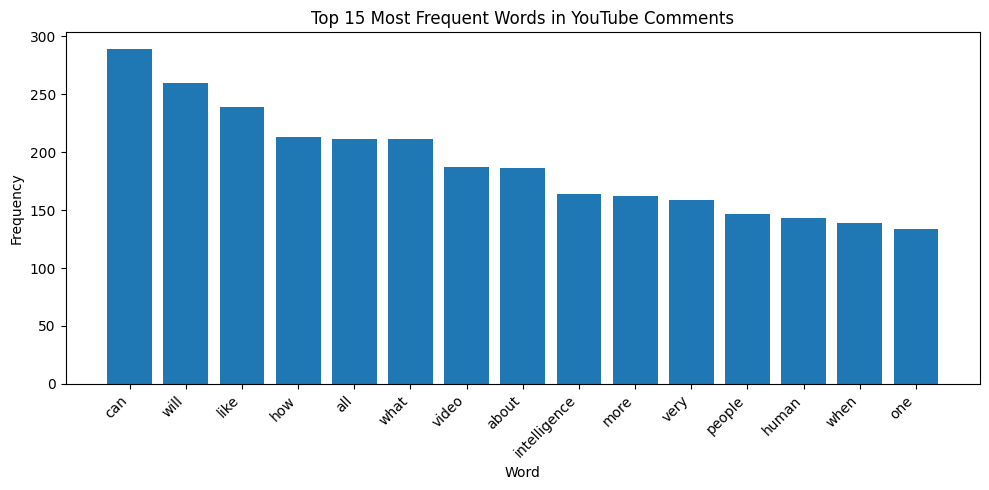

In [6]:

from collections import Counter
import matplotlib.pyplot as plt

# Combine all cleaned comments
all_comments = " ".join(
    comments_df["clean_comment"].fillna("")
)

# Split into words
words = all_comments.split()

# Remove common words that don't tell us much
stop_words = {
    "the", "a", "an", "and", "is", "it", "to", "of",
    "in", "for", "on", "that", "this", "i", "you",
    "we", "they", "are", "was", "be", "have", "has",
    "with", "but", "not", "so", "if", "my", "me",
    "your", "just", "its", "as", "at", "or", "from"
}

filtered_words = [
    word for word in words
    if word not in stop_words and len(word) > 2
]

word_counts = Counter(filtered_words).most_common(15)

word_df = pd.DataFrame(
    word_counts,
    columns=["word", "frequency"]
)

display(word_df)

# Plot the most frequent words
plt.figure(figsize=(10, 5))
plt.bar(word_df["word"], word_df["frequency"])
plt.xticks(rotation=45, ha="right")
plt.title("Top 15 Most Frequent Words in YouTube Comments")
plt.xlabel("Word")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

# Save results
word_df.to_csv(
    os.path.join(DATA_DIR, "top_comment_words.csv"),
    index=False
)


In [7]:

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Combine each video's title and description
videos_df["combined_text"] = (
    videos_df["clean_title"].fillna("") + " " +
    videos_df["clean_description"].fillna("")
)

# Convert text into numerical TF-IDF features
tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=5000
)

tfidf_matrix = tfidf.fit_transform(videos_df["combined_text"])

print("Number of videos:", len(videos_df))
print("TF-IDF matrix shape:", tfidf_matrix.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


Number of videos: 30
TF-IDF matrix shape: (30, 324)
Vocabulary size: 324


In [8]:

# Calculate similarity between every pair of videos
similarity_matrix = cosine_similarity(tfidf_matrix)

print("Similarity matrix shape:", similarity_matrix.shape)

# Recommendation function
def recommend_videos(video_index, top_n=5):
    # Get similarities for the selected video
    scores = list(enumerate(similarity_matrix[video_index]))

    # Remove the selected video itself
    scores = [
        item for item in scores
        if item[0] != video_index
    ]

    # Sort by similarity, highest first
    scores = sorted(
        scores,
        key=lambda item: item[1],
        reverse=True
    )

    # Select the top recommendations
    top_scores = scores[:top_n]

    results = []

    for index, score in top_scores:
        results.append({
            "title": videos_df.iloc[index]["title"],
            "channel": videos_df.iloc[index]["channel"],
            "similarity_score": round(float(score), 4),
            "video_url": (
                "https://www.youtube.com/watch?v=" +
                str(videos_df.iloc[index]["video_id"])
            )
        })

    return pd.DataFrame(results)

# Test the system using the first video
print("Selected video:")
print(videos_df.iloc[0]["title"])

recommendations = recommend_videos(0, top_n=5)

display(recommendations)


Similarity matrix shape: (30, 30)
Selected video:
How books are being scanned and destroyed to train artificial intelligence • FRANCE 24 English


,title,channel,similarity_score,video_url
0,artificial intelligence(SLOWED),JG,0.0871,https://www.youtube.com/watch?v=F-pMp8AaXvw
1,What Is AI? | Artificial Intelligence | What i...,Simplilearn,0.0723,https://www.youtube.com/watch?v=ad79nYk2keg
2,🧠 Artificial Intelligence Essay ✍️,Letter Writer,0.0701,https://www.youtube.com/watch?v=SKk82S_Wx_I
3,How Artificial Intelligence Is Reshaping the W...,World Governments Summit,0.0619,https://www.youtube.com/watch?v=XNbE8Awc8Z8
4,Artificial Intelligence Full Course | Artifici...,edureka!,0.0594,https://www.youtube.com/watch?v=JMUxmLyrhSk


In [9]:

# Generate recommendations for every video
all_recommendations = []

for i in range(len(videos_df)):
    recs = recommend_videos(i, top_n=5)

    for _, row in recs.iterrows():
        all_recommendations.append({
            "source_video": videos_df.iloc[i]["title"],
            "recommended_video": row["title"],
            "recommended_channel": row["channel"],
            "similarity_score": row["similarity_score"],
            "video_url": row["video_url"]
        })

recommendations_df = pd.DataFrame(all_recommendations)

recommendations_path = os.path.join(
    DATA_DIR, "video_recommendations.csv"
)

recommendations_df.to_csv(
    recommendations_path,
    index=False,
    encoding="utf-8-sig"
)

print("Total recommendations:", len(recommendations_df))
print("Saved to:", recommendations_path)

display(recommendations_df.head(10))


Total recommendations: 150
Saved to: /content/drive/MyDrive/AI_YouTube_Project/data/video_recommendations.csv


,source_video,recommended_video,recommended_channel,similarity_score,video_url
0,How books are being scanned and destroyed to t...,artificial intelligence(SLOWED),JG,0.0871,https://www.youtube.com/watch?v=F-pMp8AaXvw
1,How books are being scanned and destroyed to t...,What Is AI? | Artificial Intelligence | What i...,Simplilearn,0.0723,https://www.youtube.com/watch?v=ad79nYk2keg
2,How books are being scanned and destroyed to t...,🧠 Artificial Intelligence Essay ✍️,Letter Writer,0.0701,https://www.youtube.com/watch?v=SKk82S_Wx_I
3,How books are being scanned and destroyed to t...,How Artificial Intelligence Is Reshaping the W...,World Governments Summit,0.0619,https://www.youtube.com/watch?v=XNbE8Awc8Z8
4,How books are being scanned and destroyed to t...,Artificial Intelligence Full Course | Artifici...,edureka!,0.0594,https://www.youtube.com/watch?v=JMUxmLyrhSk
5,How Artificial Intelligence Is Reshaping the W...,artificial intelligence(SLOWED),JG,0.1382,https://www.youtube.com/watch?v=F-pMp8AaXvw
6,How Artificial Intelligence Is Reshaping the W...,What Is AI? | Artificial Intelligence | What i...,Simplilearn,0.1147,https://www.youtube.com/watch?v=ad79nYk2keg
7,How Artificial Intelligence Is Reshaping the W...,Elon Musk on AI: humans will no longer be in c...,The Economist,0.0956,https://www.youtube.com/watch?v=1X-rr1DKSbY
8,How Artificial Intelligence Is Reshaping the W...,Artificial Intelligence Full Course | Artifici...,edureka!,0.0942,https://www.youtube.com/watch?v=JMUxmLyrhSk
9,How Artificial Intelligence Is Reshaping the W...,What Is AI? | Learn all about artificial intel...,Learn Bright,0.0926,https://www.youtube.com/watch?v=JcXKbUIebrU


In [1]:

!pip -q install transformers torch


In [10]:

import torch
import pandas as pd
import os
from transformers import pipeline

# Use GPU if Colab provides one; otherwise use CPU
device = 0 if torch.cuda.is_available() else -1

print("Device:", "GPU" if device == 0 else "CPU")

classifier = pipeline(
    "zero-shot-classification",
    model="facebook/bart-large-mnli",
    device=device
)

print("Zero-shot classification model loaded successfully.")


Device: GPU


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Zero-shot classification model loaded successfully.


In [1]:
import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
PROJECT_DIR = "/content/drive/MyDrive/AI_YouTube_Project"
DATA_DIR = os.path.join(PROJECT_DIR, "data")
OUTPUT_DIR = os.path.join(PROJECT_DIR, "output")

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Project folder:", PROJECT_DIR)
print("Data folder:", DATA_DIR)

Project folder: /content/drive/MyDrive/AI_YouTube_Project
Data folder: /content/drive/MyDrive/AI_YouTube_Project/data


In [11]:

# Load your existing comments
comments_df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments.csv")
)

candidate_labels = [
    "benefits and positive uses of artificial intelligence",
    "job losses, employment, and workplace automation caused by AI",
    "privacy, surveillance, and personal data concerns about AI",
    "copyright, creative ownership, and AI training data",
    "AI safety, misinformation, deepfakes, and harmful uses",
    "education, learning, and studying artificial intelligence"
]

# A conservative starting threshold, to be checked against examples
CONFIDENCE_THRESHOLD = 0.40

texts = (
    comments_df["comment"]
    .fillna("")
    .astype(str)
    .tolist()
)

# Avoid sending empty comments to the model
results = [None] * len(texts)
valid_indices = [
    i for i, text in enumerate(texts) if text.strip()
]

# Process in batches to limit memory usage
BATCH_SIZE = 8

for start in range(0, len(valid_indices), BATCH_SIZE):
    batch_indices = valid_indices[start:start + BATCH_SIZE]
    batch_texts = [texts[i] for i in batch_indices]

    batch_results = classifier(
        batch_texts,
        candidate_labels=candidate_labels,
        multi_label=False,
        batch_size=BATCH_SIZE,
        truncation=True
    )

    if isinstance(batch_results, dict):
        batch_results = [batch_results]

    for i, result in zip(batch_indices, batch_results):
        results[i] = result

# Save the top topic and its score
comments_df["predicted_topic"] = [
    result["labels"][0] if result else "Empty comment"
    for result in results
]

comments_df["topic_score"] = [
    float(result["scores"][0]) if result else 0.0
    for result in results
]

comments_df["topic"] = comments_df.apply(
    lambda row: (
        row["predicted_topic"]
        if row["topic_score"] >= CONFIDENCE_THRESHOLD
        and row["predicted_topic"] != "Empty comment"
        else "Uncertain / Other"
    ),
    axis=1
)

# Save classified comments to Google Drive
classified_path = os.path.join(
    DATA_DIR, "youtube_comments_topics.csv"
)

comments_df.to_csv(
    classified_path,
    index=False,
    encoding="utf-8-sig"
)

print("Comments processed:", len(comments_df))
print("Saved to:", classified_path)

display(
    comments_df[
        ["comment", "predicted_topic", "topic_score", "topic"]
    ].head(10)
)


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Comments processed: 2299
Saved to: /content/drive/MyDrive/AI_YouTube_Project/data/youtube_comments_topics.csv


,comment,predicted_topic,topic_score,topic
0,"This is, more than anything, pure evil.","AI safety, misinformation, deepfakes, and harm...",0.271846,Uncertain / Other
1,This should be illegal. They'll gate keep the ...,"AI safety, misinformation, deepfakes, and harm...",0.226408,Uncertain / Other
2,I dont have a lot of money but I have started ...,"privacy, surveillance, and personal data conce...",0.232428,Uncertain / Other
3,"so that no one can study on their own anymore,...","education, learning, and studying artificial i...",0.507004,"education, learning, and studying artificial i..."
4,"Scanning fine, destroying? That’s the part tha...","privacy, surveillance, and personal data conce...",0.221745,Uncertain / Other
5,They are desperate for pre-AI written text... ...,"education, learning, and studying artificial i...",0.444673,"education, learning, and studying artificial i..."
6,I love how these bookstores complain but never...,"copyright, creative ownership, and AI training...",0.235269,Uncertain / Other
7,They should just release the digitized version...,benefits and positive uses of artificial intel...,0.574445,benefits and positive uses of artificial intel...
8,If the books are out of copyright maybe they c...,"copyright, creative ownership, and AI training...",0.508205,"copyright, creative ownership, and AI training..."
9,Nationalize this knowledge. Amazon does not ow...,"copyright, creative ownership, and AI training...",0.585301,"copyright, creative ownership, and AI training..."


In [13]:
topic_counts = (
    result_df["topic"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Comments")
)

topic_counts["Percentage"] = (
    topic_counts["Comments"] / len(result_df) * 100
).round(2)

display(topic_counts)

# Save summary to Drive
summary_path = os.path.join(DATA_DIR, "topic_summary.csv")
topic_counts.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("Summary saved to:", summary_path)

,Topic,Comments,Percentage
0,Uncertain / Other,1609,69.99
1,benefits and positive uses of artificial intel...,398,17.31
2,"education, learning, and studying artificial i...",206,8.96
3,"AI safety, misinformation, deepfakes, and harm...",30,1.30
4,"job losses, employment, and workplace automati...",25,1.09
5,"privacy, surveillance, and personal data conce...",23,1.00
6,"copyright, creative ownership, and AI training...",8,0.35


Summary saved to: /content/drive/MyDrive/AI_YouTube_Project/data/topic_summary.csv


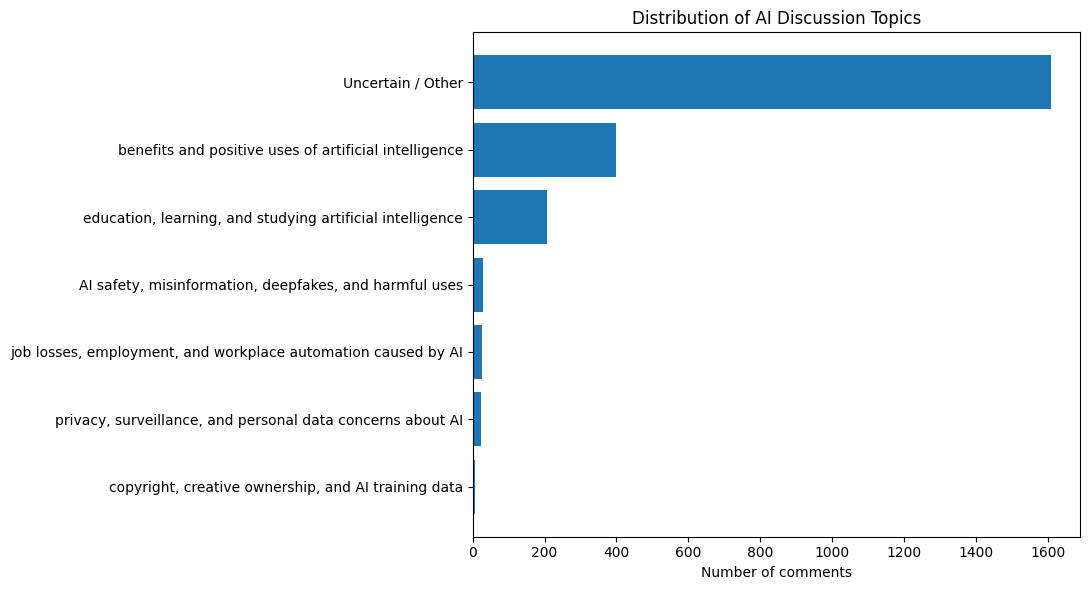

In [14]:
import matplotlib.pyplot as plt

chart_data = topic_counts.sort_values("Comments")

plt.figure(figsize=(11, 6))
plt.barh(chart_data["Topic"], chart_data["Comments"])
plt.xlabel("Number of comments")
plt.title("Distribution of AI Discussion Topics")
plt.tight_layout()
plt.show()

The uncertain categories contains irrelevent data like we had message, Thank you from Brazil etc


In [15]:
uncertain_comments = result_df.loc[
    result_df["topic"] == "Uncertain / Other",
    ["comment", "predicted_topic", "topic_score"]
].copy()

display(uncertain_comments.sample(
    min(30, len(uncertain_comments)),
    random_state=42
))

,comment,predicted_topic,topic_score
39,❤ Copyright Notice & Declaration of Original W...,"copyright, creative ownership, and AI training...",0.302549
130,"if my eyes are red, i rubbed them",benefits and positive uses of artificial intel...,0.238648
1013,That end bit... Steven's gotcha and Roman's la...,"copyright, creative ownership, and AI training...",0.210868
2016,"""I think I owe that to the James Bond franchis...",benefits and positive uses of artificial intel...,0.293778
222,Excellent Tutorial with understandable English...,"education, learning, and studying artificial i...",0.263503
1329,"At the end of civilization as suggested, but n...","copyright, creative ownership, and AI training...",0.245556
1638,"Remember, guys - he sells AI for a living.",benefits and positive uses of artificial intel...,0.394748
1319,How close are we from it really?,"copyright, creative ownership, and AI training...",0.192376
1233,Now that was a really good presentation.,benefits and positive uses of artificial intel...,0.313089
1960,"Tom, just wanted to say love your podcast. You...","education, learning, and studying artificial i...",0.203433


In [16]:
import os
import torch
import pandas as pd
from transformers import pipeline

# Check GPU
if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU not detected. Select T4 GPU and rerun the setup cells."
    )

# Load model only if it is not already available
if "classifier" not in globals():
    classifier = pipeline(
        "zero-shot-classification",
        model="facebook/bart-large-mnli",
        device=0
    )

print("Using GPU:", torch.cuda.get_device_name(0))

# Load existing files
comments_df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments.csv")
)
videos_df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_videos.csv")
)

# Match each comment to its video's title
comments_df["video_id"] = comments_df["video_id"].astype(str)
videos_df["video_id"] = videos_df["video_id"].astype(str)

title_map = videos_df.set_index("video_id")["title"].to_dict()

comments_df["video_title"] = (
    comments_df["video_id"].map(title_map).fillna("")
)

# Separate checkpoint and final output files
checkpoint_path = os.path.join(
    DATA_DIR, "youtube_two_stage_checkpoint.csv"
)
final_path = os.path.join(
    DATA_DIR, "youtube_comments_improved_analysis.csv"
)

# Classification settings
BATCH_SIZE = 16
RELEVANCE_THRESHOLD = 0.55
TOPIC_THRESHOLD = 0.40

candidate_topics = [
    "benefits and positive uses of artificial intelligence",
    "job losses, employment, and workplace automation caused by AI",
    "privacy, surveillance, and personal data concerns about AI",
    "copyright, creative ownership, and AI training data",
    "AI safety, misinformation, deepfakes, and harmful uses",
    "education, learning, and studying artificial intelligence"
]

# Load previous checkpoint if it matches this dataset
checkpoint_columns = [
    "relevance_label",
    "relevance_score",
    "predicted_topic",
    "topic_score"
]

if os.path.exists(checkpoint_path):
    saved = pd.read_csv(checkpoint_path)

    if len(saved) == len(comments_df):
        for col in checkpoint_columns:
            if col in saved.columns:
                comments_df[col] = saved[col]
            else:
                comments_df[col] = None
        print("Loaded previous checkpoint.")
    else:
        print("Checkpoint row count differs; starting a new analysis.")
        for col in checkpoint_columns:
            comments_df[col] = None
else:
    for col in checkpoint_columns:
        comments_df[col] = None

def save_checkpoint():
    comments_df.to_csv(
        checkpoint_path,
        index=False,
        encoding="utf-8-sig"
    )

# --------------------------------------------------
# STAGE 1: Is the comment relevant to its video?
# --------------------------------------------------

relevance_labels = [
    "a comment meaningfully discussing the video's subject",
    "a generic reaction, greeting, praise, joke, or unrelated comment"
]

pending = [
    i for i, row in comments_df.iterrows()
    if str(row["comment"]).strip()
    and pd.isna(row["relevance_label"])
]

print("Stage 1: comments needing relevance analysis:", len(pending))

for start in range(0, len(pending), BATCH_SIZE):
    indices = pending[start:start + BATCH_SIZE]

    batch_texts = [
        "Video title: " + str(comments_df.at[i, "video_title"])
        + "\nComment: " + str(comments_df.at[i, "comment"])
        for i in indices
    ]

    predictions = classifier(
        batch_texts,
        candidate_labels=relevance_labels,
        multi_label=False,
        batch_size=BATCH_SIZE,
        truncation=True
    )

    if isinstance(predictions, dict):
        predictions = [predictions]

    for i, pred in zip(indices, predictions):
        comments_df.at[i, "relevance_label"] = pred["labels"][0]
        comments_df.at[i, "relevance_score"] = float(pred["scores"][0])

    save_checkpoint()
    print(
        f"Relevance stage: {min(start + BATCH_SIZE, len(pending))}"
        f"/{len(pending)} batches' comments processed"
    )

# Assign a transparent relevance decision
relevant_label = relevance_labels[0]

comments_df["relevance"] = comments_df.apply(
    lambda row: (
        "Relevant"
        if row["relevance_label"] == relevant_label
        and pd.notna(row["relevance_score"])
        and float(row["relevance_score"]) >= RELEVANCE_THRESHOLD
        else (
            "Generic / Off-topic"
            if row["relevance_label"] == relevance_labels[1]
            and pd.notna(row["relevance_score"])
            and float(row["relevance_score"]) >= RELEVANCE_THRESHOLD
            else "Uncertain relevance"
        )
    ),
    axis=1
)

save_checkpoint()

# --------------------------------------------------
# STAGE 2: Classify relevant comments into AI topics
# --------------------------------------------------

pending = [
    i for i, row in comments_df.iterrows()
    if row["relevance"] == "Relevant"
    and str(row["comment"]).strip()
    and pd.isna(row["predicted_topic"])
]

print("\nStage 2: relevant comments needing topic analysis:", len(pending))

for start in range(0, len(pending), BATCH_SIZE):
    indices = pending[start:start + BATCH_SIZE]

    batch_texts = [
        "Video title: " + str(comments_df.at[i, "video_title"])
        + "\nComment: " + str(comments_df.at[i, "comment"])
        for i in indices
    ]

    predictions = classifier(
        batch_texts,
        candidate_labels=candidate_topics,
        multi_label=False,
        batch_size=BATCH_SIZE,
        truncation=True
    )

    if isinstance(predictions, dict):
        predictions = [predictions]

    for i, pred in zip(indices, predictions):
        comments_df.at[i, "predicted_topic"] = pred["labels"][0]
        comments_df.at[i, "topic_score"] = float(pred["scores"][0])

    save_checkpoint()
    print(
        f"Topic stage: {min(start + BATCH_SIZE, len(pending))}"
        f"/{len(pending)} comments processed"
    )

# --------------------------------------------------
# Final labels and save
# --------------------------------------------------

def final_topic(row):
    if row["relevance"] != "Relevant":
        return row["relevance"]

    if pd.isna(row["predicted_topic"]):
        return "Topic analysis pending"

    if float(row["topic_score"]) < TOPIC_THRESHOLD:
        return "Uncertain topic"

    return row["predicted_topic"]

comments_df["final_topic"] = comments_df.apply(final_topic, axis=1)

comments_df.to_csv(
    final_path,
    index=False,
    encoding="utf-8-sig"
)

save_checkpoint()

print("\nAnalysis complete!")
print("Comments analyzed:", len(comments_df))
print("Final file:", final_path)

print("\nRelevance summary:")
display(comments_df["relevance"].value_counts().to_frame("Comments"))

print("\nFinal topic summary:")
display(comments_df["final_topic"].value_counts().to_frame("Comments"))

display(
    comments_df[
        ["video_title", "comment", "relevance",
         "relevance_score", "final_topic", "topic_score"]
    ].head(10)
)

Using GPU: Tesla T4
Stage 1: comments needing relevance analysis: 2299
Relevance stage: 16/2299 batches' comments processed
Relevance stage: 32/2299 batches' comments processed
Relevance stage: 48/2299 batches' comments processed
Relevance stage: 64/2299 batches' comments processed
Relevance stage: 80/2299 batches' comments processed
Relevance stage: 96/2299 batches' comments processed
Relevance stage: 112/2299 batches' comments processed
Relevance stage: 128/2299 batches' comments processed
Relevance stage: 144/2299 batches' comments processed
Relevance stage: 160/2299 batches' comments processed
Relevance stage: 176/2299 batches' comments processed
Relevance stage: 192/2299 batches' comments processed
Relevance stage: 208/2299 batches' comments processed
Relevance stage: 224/2299 batches' comments processed
Relevance stage: 240/2299 batches' comments processed
Relevance stage: 256/2299 batches' comments processed
Relevance stage: 272/2299 batches' comments processed
Relevance stage: 

,Comments
relevance,
Relevant,2289
Generic / Off-topic,7
Uncertain relevance,3



Final topic summary:


,Comments
final_topic,
"education, learning, and studying artificial intelligence",1158
Uncertain topic,590
benefits and positive uses of artificial intelligence,443
"AI safety, misinformation, deepfakes, and harmful uses",42
"privacy, surveillance, and personal data concerns about AI",21
"job losses, employment, and workplace automation caused by AI",18
"copyright, creative ownership, and AI training data",17
Generic / Off-topic,7
Uncertain relevance,3


,video_title,comment,relevance,relevance_score,final_topic,topic_score
0,How books are being scanned and destroyed to t...,"This is, more than anything, pure evil.",Relevant,0.985418,Uncertain topic,0.270354
1,How books are being scanned and destroyed to t...,This should be illegal. They'll gate keep the ...,Relevant,0.964553,Uncertain topic,0.333544
2,How books are being scanned and destroyed to t...,I dont have a lot of money but I have started ...,Relevant,0.874297,Uncertain topic,0.39989
3,How books are being scanned and destroyed to t...,"so that no one can study on their own anymore,...",Relevant,0.97757,"education, learning, and studying artificial i...",0.672451
4,How books are being scanned and destroyed to t...,"Scanning fine, destroying? That’s the part tha...",Relevant,0.991277,Uncertain topic,0.299345
5,How books are being scanned and destroyed to t...,They are desperate for pre-AI written text... ...,Relevant,0.924425,"education, learning, and studying artificial i...",0.706494
6,How books are being scanned and destroyed to t...,I love how these bookstores complain but never...,Relevant,0.651486,"education, learning, and studying artificial i...",0.566357
7,How books are being scanned and destroyed to t...,They should just release the digitized version...,Relevant,0.843881,"education, learning, and studying artificial i...",0.559208
8,How books are being scanned and destroyed to t...,If the books are out of copyright maybe they c...,Relevant,0.771178,"copyright, creative ownership, and AI training...",0.704867
9,How books are being scanned and destroyed to t...,Nationalize this knowledge. Amazon does not ow...,Relevant,0.97333,"copyright, creative ownership, and AI training...",0.808678


In [17]:
import os
import pandas as pd

# Load the completed analysis
analysis_path = os.path.join(
    DATA_DIR, "youtube_comments_improved_analysis.csv"
)

df = pd.read_csv(analysis_path)

# Separate comment groups
relevant = df[df["relevance"] == "Relevant"].copy()

generic = df[
    df["relevance"] == "Generic / Off-topic"
].copy()

uncertain_relevance = df[
    df["relevance"] == "Uncertain relevance"
].copy()

uncertain_topic = df[
    df["final_topic"] == "Uncertain topic"
].copy()

# Save each group separately
files_to_save = {
    "relevant_comments.csv": relevant,
    "generic_comments.csv": generic,
    "uncertain_relevance_comments.csv": uncertain_relevance,
    "uncertain_topic_comments.csv": uncertain_topic
}

for filename, data in files_to_save.items():
    path = os.path.join(DATA_DIR, filename)
    data.to_csv(path, index=False, encoding="utf-8-sig")
    print(f"{filename}: {len(data)} rows saved")

# Build a topic summary excluding uncertain and generic labels
excluded_labels = [
    "Uncertain topic",
    "Generic / Off-topic",
    "Uncertain relevance",
    "Topic analysis pending"
]

topic_summary = (
    df[~df["final_topic"].isin(excluded_labels)]
    ["final_topic"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Comments")
)

# Percentage among comments assigned to a specific topic
total_classified = topic_summary["Comments"].sum()

if total_classified > 0:
    topic_summary["Percentage"] = (
        topic_summary["Comments"] / total_classified * 100
    ).round(2)

summary_path = os.path.join(DATA_DIR, "topic_summary.csv")
topic_summary.to_csv(
    summary_path, index=False, encoding="utf-8-sig"
)

print("\nTopic summary saved:", summary_path)
display(topic_summary)

relevant_comments.csv: 2289 rows saved
generic_comments.csv: 7 rows saved
uncertain_relevance_comments.csv: 3 rows saved
uncertain_topic_comments.csv: 590 rows saved

Topic summary saved: /content/drive/MyDrive/AI_YouTube_Project/data/topic_summary.csv


,Topic,Comments,Percentage
0,"education, learning, and studying artificial i...",1158,68.16
1,benefits and positive uses of artificial intel...,443,26.07
2,"AI safety, misinformation, deepfakes, and harm...",42,2.47
3,"privacy, surveillance, and personal data conce...",21,1.24
4,"job losses, employment, and workplace automati...",18,1.06
5,"copyright, creative ownership, and AI training...",17,1.00


In [18]:
import os
import pandas as pd

analysis_path = os.path.join(
    DATA_DIR, "youtube_comments_improved_analysis.csv"
)
df = pd.read_csv(analysis_path)

topics_to_check = [
    "education, learning, and studying artificial intelligence",
    "benefits and positive uses of artificial intelligence",
    "copyright, creative ownership, and AI training data"
]

for topic in topics_to_check:
    sample = df[df["final_topic"] == topic]
    print(f"\nTOPIC: {topic} | Total: {len(sample)}")

    if len(sample) > 0:
        display(sample[
            ["video_title", "comment", "topic_score"]
        ].sample(min(8, len(sample)), random_state=42))


TOPIC: education, learning, and studying artificial intelligence | Total: 1158


,video_title,comment,topic_score
1862,Artificial Intelligence (Official Video),Damn the break @2:45 and the build up followin...,0.402464
437,SIMPLEST Explanation of How Artificial Intelli...,I'm 80 years old and just like AI still learni...,0.928823
267,AI Simplified: 6 Concepts You Need to Know Abo...,Well explained 😊. ❤,0.850739
474,SIMPLEST Explanation of How Artificial Intelli...,"Super, Subhaanallah_ Syukr Bro!",0.661845
1490,The Next 10 Years of AI Will Change Everything...,10 years later: The next 10 years in AI will c...,0.445158
337,What Is AI? | Artificial Intelligence | What i...,I have no knowledge about AI but this video ha...,0.788206
1739,Artificial Intelligence Full Course | Artifici...,This one of the best tutorials thank you so mu...,0.950184
856,🧠 Artificial Intelligence Essay ✍️,❤❤❤❤❤❤,0.633670



TOPIC: benefits and positive uses of artificial intelligence | Total: 443


,video_title,comment,topic_score
1857,Artificial Intelligence (Official Video),"After listening to this about a hundred times,...",0.431513
1232,AI progress is speeding up dramatically - here...,"Just remember, Ai's greatest fear, is the plug...",0.780436
1089,Artificial Intelligence | 60 Minutes Full Epis...,This is really outstanding mainstream journali...,0.411699
1947,THIS is What&#39;s REALLY Happening With AI Sa...,You are arguing romans point. NARROW TOOL is t...,0.492730
1095,Artificial Intelligence | 60 Minutes Full Epis...,"Acttually, when the computer was invented and ...",0.789139
1650,Elon Musk on AI: humans will no longer be in c...,"Abundance for a few , please stop saying it!!!!",0.437887
2081,Artificial Intelligence in 2025 | 60 Minutes F...,I hope the people suffering from paralysis con...,0.771801
1445,Artificial Intelligence: Complete path to 2030,oh man how am I just seeing this right now??!!!,0.436826



TOPIC: copyright, creative ownership, and AI training data | Total: 17


,video_title,comment,topic_score
8,How books are being scanned and destroyed to t...,If the books are out of copyright maybe they c...,0.704867
9,How books are being scanned and destroyed to t...,Nationalize this knowledge. Amazon does not ow...,0.808678
32,How books are being scanned and destroyed to t...,Please keep the books for future generations.,0.415263
76,How books are being scanned and destroyed to t...,Copy right and the author’s right are not defi...,0.747019
52,How books are being scanned and destroyed to t...,Sounds like the plot of a sci-fi movie.,0.431593
63,How books are being scanned and destroyed to t...,"People, don't sell your books!",0.483712
45,How books are being scanned and destroyed to t...,❤ A grandfather clause is a legal provision th...,0.749438
58,How books are being scanned and destroyed to t...,The Internet Archive should be allowed to scan...,0.443380


### Improved Comment Classification

The initial analysis showed that some comments were assigned incorrect topics. To reduce this issue, comments are now classified without using video titles, and a general AI discussion category is included.

Comments with low confidence are marked as uncertain rather than automatically treated as correct. Sample predictions should still be reviewed manually.

**Limitation:** Zero-shot classification uses a pretrained model; it is not trained specifically on our collected dataset.

In [ ]:
import os
import pandas as pd
from tqdm.auto import tqdm

# Load existing results
df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments_improved_analysis.csv")
)
df["comment"] = df["comment"].fillna("").astype(str)

# Stage 1: Is the comment meaningful or just a generic reaction?
relevance_labels = [
    "a meaningful comment discussing artificial intelligence",
    "a generic reaction, praise, greeting, joke, or unrelated comment"
]

# Stage 2: More balanced topic categories, including a fallback
topic_labels = [
    "education, learning, and studying artificial intelligence",
    "benefits and useful applications of artificial intelligence",
    "job losses and workplace automation caused by AI",
    "privacy, surveillance, and personal data concerns about AI",
    "copyright, creative ownership, and AI training data",
    "AI safety, misinformation, deepfakes, and harmful uses",
    "general AI discussion that does not fit the other topics"
]

comments = df["comment"].tolist()
relevance_results = []
topic_results = []

BATCH_SIZE = 16

# Classify comments without video titles
for start in tqdm(range(0, len(comments), BATCH_SIZE)):
    batch = comments[start:start + BATCH_SIZE]
    results = classifier(
        batch,
        candidate_labels=relevance_labels,
        multi_label=False
    )
    relevance_results.extend(results)

# Save relevance predictions and classify topics
for i, result in enumerate(relevance_results):
    label = result["labels"][0]
    score = float(result["scores"][0])

    if score < 0.60:
        df.loc[i, "relevance"] = "Uncertain relevance"
        df.loc[i, "final_topic"] = "Uncertain relevance"
    elif label == relevance_labels[1]:
        df.loc[i, "relevance"] = "Generic / Off-topic"
        df.loc[i, "final_topic"] = "Generic / Off-topic"
    else:
        df.loc[i, "relevance"] = "Relevant"

        topic_result = classifier(
            comments[i],
            candidate_labels=topic_labels,
            multi_label=False
        )
        topic_label = topic_result["labels"][0]
        topic_score = float(topic_result["scores"][0])

        df.loc[i, "predicted_topic"] = topic_label
        df.loc[i, "topic_score"] = topic_score

        if topic_score < 0.40:
            df.loc[i, "final_topic"] = "Uncertain topic"
        else:
            df.loc[i, "final_topic"] = topic_label

# Save improved analysis separately
output_path = os.path.join(
    DATA_DIR, "youtube_comments_validated_v2.csv"
)
df.to_csv(output_path, index=False, encoding="utf-8-sig")

print("Saved:", output_path)
print("\nFinal topic counts:")
display(df["final_topic"].value_counts().to_frame("Comments"))

### Preliminary Results

The second analysis processed 2,299 YouTube comments using a pretrained zero-shot NLP model. It introduced a general AI discussion category and separated uncertain predictions from generic reactions.

The results remain preliminary because short comments, jokes, and ambiguous opinions can be misclassified. Manual sample inspection is required before interpreting topic counts as public opinion.

In [20]:
# Inspect samples from the new analysis
df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments_validated_v2.csv")
)

for category in [
    "Generic / Off-topic",
    "Uncertain relevance",
    "general AI discussion that does not fit the other topics",
    "benefits and useful applications of artificial intelligence"
]:
    subset = df[df["final_topic"] == category]

    print(f"\n{category} — {len(subset)} comments")

    if len(subset) > 0:
        display(subset[["video_title", "comment"]].sample(
            min(5, len(subset)), random_state=42
        ))


Generic / Off-topic — 903 comments


,video_title,comment
141,artificial intelligence(SLOWED),"If I have have brown trails behind me, I have ..."
1184,AI progress is speeding up dramatically - here...,I don't know but this presentation was done so...
504,SIMPLEST Explanation of How Artificial Intelli...,I’m dangerously confident now. Thanks a lot.
640,"AI, Machine Learning, Deep Learning and Genera...",The line he drew at 5:33 was so clean
97,How books are being scanned and destroyed to t...,People called me a conspiracy theorist when I ...



Uncertain relevance — 372 comments


,video_title,comment
2037,Artificial Intelligence in 2025 | 60 Minutes F...,Devs - The mini series. Really good
179,artificial intelligence(SLOWED),This good music for locking in on assets Corsa .
67,How books are being scanned and destroyed to t...,"Purposely destroying books, something sinister..."
1962,THIS is What&#39;s REALLY Happening With AI Sa...,A product cannot succeed when it's value spect...
304,AI Simplified: 6 Concepts You Need to Know Abo...,I like to have one. Thanks for tutorial.



general AI discussion that does not fit the other topics — 158 comments


,video_title,comment
1912,THIS is What&#39;s REALLY Happening With AI Sa...,"The one thing I love about this is ""It was gro..."
898,Bill Gates calls AI ‘the most dangerous techno...,Rewarding superintelligent AI for unaliving pe...
1931,THIS is What&#39;s REALLY Happening With AI Sa...,"Tom, you’ve had Roman on, and I bet he used hi..."
2157,How China Is Using Artificial Intelligence in ...,This is like a mental prison for students. As ...
1355,Here&#39;s the difference between regular AI a...,Why don't those researchers have a debate with...



benefits and useful applications of artificial intelligence — 143 comments


,video_title,comment
1772,Artificial Intelligence Full Course | Artifici...,Thank You Edureka ❤
377,What Is AI? | Artificial Intelligence | What i...,D.robot that develops emotions over time.
1127,Artificial Intelligence | 60 Minutes Full Epis...,Imagine an insurance company that was evaluati...
1362,Here&#39;s the difference between regular AI a...,Will Robinson has a Ai that was very helpful.....
641,"AI, Machine Learning, Deep Learning and Genera...",The fascinating part is how these terms are of...


### Results and Limitations

The collected data was analyzed using NLP and similarity-based recommendation techniques. Topic classification is exploratory and requires manual validation. Results will be presented with these limitations clearly stated.

In [21]:
import os
import pandas as pd

OUTPUT_DIR = os.path.join(PROJECT_DIR, "output")
os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(
    os.path.join(DATA_DIR, "youtube_comments_validated_v2.csv")
)

summary = (
    df["final_topic"]
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Comments")
)
summary["Percentage"] = (
    summary["Comments"] / len(df) * 100
).round(2)

summary.to_csv(
    os.path.join(OUTPUT_DIR, "final_topic_summary.csv"),
    index=False,
    encoding="utf-8-sig"
)

report = f"""# AI-Powered YouTube Content Analysis

## Objective
Analyze YouTube video metadata and comments using basic NLP,
then recommend similar videos.

## Dataset
- Videos collected: {df['video_id'].nunique()}
- Comments analyzed: {len(df)}

## Methodology
- YouTube Data API for public video and comment data
- TF-IDF and cosine similarity for video recommendations
- Pretrained zero-shot NLP model for exploratory comment classification
- Manual inspection of sample predictions

## Limitation
Comment classifications are preliminary. Short comments, jokes,
and ambiguous opinions may be misclassified. Topic counts should
not be interpreted as reliable measures of public opinion.

## Topic Counts
""" + summary.to_markdown(index=False)

with open(
    os.path.join(OUTPUT_DIR, "project_summary.md"),
    "w",
    encoding="utf-8"
) as f:
    f.write(report)

print("Saved topic summary and Markdown report in:", OUTPUT_DIR)
display(summary)


Saved topic summary and Markdown report in: /content/drive/MyDrive/AI_YouTube_Project/output


,Topic,Comments,Percentage
0,Generic / Off-topic,903,39.28
1,Uncertain topic,566,24.62
2,Uncertain relevance,372,16.18
3,general AI discussion that does not fit the ot...,158,6.87
4,benefits and useful applications of artificial...,143,6.22
5,"education, learning, and studying artificial i...",128,5.57
6,"privacy, surveillance, and personal data conce...",11,0.48
7,job losses and workplace automation caused by AI,10,0.43
8,"AI safety, misinformation, deepfakes, and harm...",6,0.26
9,"copyright, creative ownership, and AI training...",2,0.09


### Final Report Preparation

The collected video data, analyzed comments, topic counts, and video recommendations are organized into an Excel workbook. Tables are formatted for readability, and a chart summarizes the preliminary topic classifications.

The results are exploratory and should be interpreted in light of the limitations of zero-shot classification.

In [22]:
import os
import glob
import pandas as pd
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.chart import BarChart, Reference

DATA_DIR = "/content/drive/MyDrive/AI_YouTube_Project/data"
OUTPUT_DIR = "/content/drive/MyDrive/AI_YouTube_Project/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Load the main datasets
files = {
    "Video Data": "youtube_videos.csv",
    "Comment Analysis": "youtube_comments_validated_v2.csv",
    "Topic Summary": "final_topic_summary.csv",
    "Recommendations": "video_recommendations.csv"
}

datasets = {}

for sheet, filename in files.items():
    path = next(
        (p for p in [
            os.path.join(DATA_DIR, filename),
            os.path.join(OUTPUT_DIR, filename)
        ] if os.path.exists(p)),
        None
    )

    if path:
        datasets[sheet] = pd.read_csv(path)
        print(f"Loaded {sheet}: {len(datasets[sheet])} rows")
    elif sheet in ["Video Data", "Comment Analysis"]:
        raise FileNotFoundError(
            f"Could not find {filename}. Check your project folders."
        )
    else:
        print(f"Optional file not found: {filename}")

# Recreate topic summary if needed
if "Topic Summary" not in datasets:
    comments = datasets["Comment Analysis"]
    topic_summary = (
        comments["final_topic"].value_counts()
        .rename_axis("Topic").reset_index(name="Comments")
    )
    topic_summary["Percentage"] = (
        topic_summary["Comments"] / len(comments) * 100
    ).round(2)
    datasets["Topic Summary"] = topic_summary

# Create workbook
report_path = os.path.join(OUTPUT_DIR, "AI_YouTube_Project_Report.xlsx")

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    for sheet, data in datasets.items():
        data.to_excel(writer, sheet_name=sheet, index=False)

# Format sheets
wb = load_workbook(report_path)

for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="203864")
        cell.alignment = Alignment(wrap_text=True, vertical="center")

    ws.row_dimensions[1].height = 30

    for column_cells in ws.columns:
        max_length = max(
            (len(str(c.value)) for c in list(column_cells)[:200]
             if c.value is not None),
            default=10
        )
        ws.column_dimensions[column_cells[0].column_letter].width = min(
            max(max_length + 2, 12), 45
        )

# Add a chart to the topic summary sheet
if "Topic Summary" in wb.sheetnames:
    ws = wb["Topic Summary"]
    if ws.max_row > 1:
        chart = BarChart()
        chart.type = "bar"
        chart.style = 10
        chart.title = "YouTube Comment Topic Counts"
        chart.x_axis.title = "Comments"
        chart.y_axis.title = "Topic"
        chart.height = 8
        chart.width = 16

        chart.add_data(
            Reference(ws, min_col=2, min_row=1, max_row=ws.max_row),
            titles_from_data=True
        )
        chart.set_categories(
            Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)
        )
        ws.add_chart(chart, "F2")

wb.save(report_path)

print("\nExcel report created successfully:")
print(report_path)


Loaded Video Data: 30 rows
Loaded Comment Analysis: 2299 rows
Loaded Topic Summary: 10 rows
Loaded Recommendations: 150 rows

Excel report created successfully:
/content/drive/MyDrive/AI_YouTube_Project/output/AI_YouTube_Project_Report.xlsx


### Data Insights and Reporting

Video performance metrics were compared to identify the most-viewed, most-liked, and most-commented videos. Engagement rates and topic distributions were summarized using tables and charts. The content-based recommendation results were retained for inspection.

Comment topics remain preliminary because sample validation identified classification errors.

In [23]:
import os
import pandas as pd
from openpyxl import load_workbook
from openpyxl.styles import Font, PatternFill, Alignment
from openpyxl.chart import BarChart, Reference

DATA_DIR = "/content/drive/MyDrive/AI_YouTube_Project/data"
OUTPUT_DIR = "/content/drive/MyDrive/AI_YouTube_Project/output"
os.makedirs(OUTPUT_DIR, exist_ok=True)

def find_file(filename):
    for folder in [DATA_DIR, OUTPUT_DIR]:
        path = os.path.join(folder, filename)
        if os.path.exists(path):
            return path
    return None

# Load existing datasets
video_path = find_file("youtube_videos.csv")
comment_path = find_file("youtube_comments_validated_v2.csv")
recommend_path = find_file("video_recommendations.csv")

if not video_path or not comment_path:
    raise FileNotFoundError(
        "Could not find the video or comment CSV. Check your Drive folders."
    )

videos = pd.read_csv(video_path)
comments = pd.read_csv(comment_path)
recommendations = (
    pd.read_csv(recommend_path) if recommend_path else pd.DataFrame()
)

# Clean numeric columns
for col in ["views", "likes", "comments_count"]:
    if col in videos.columns:
        videos[col] = pd.to_numeric(videos[col], errors="coerce")

for col in ["views", "likes", "comments_count"]:
    if col not in videos.columns:
        videos[col] = float("nan")

videos["engagement_rate_pct"] = (
    (videos["likes"].fillna(0) + videos["comments_count"].fillna(0))
    / videos["views"].replace(0, float("nan")) * 100
).round(2)

# Performance tables
top_views = videos.nlargest(10, "views")
top_likes = videos.nlargest(10, "likes")
top_comments = videos.nlargest(10, "comments_count")

# Avoid highlighting tiny-view videos as engagement leaders
eligible = videos[videos["views"] >= 100].copy()
top_engagement = eligible.nlargest(10, "engagement_rate_pct")

# Topic counts from latest classifier output
topic_summary = (
    comments["final_topic"].fillna("Unclassified")
    .value_counts()
    .rename_axis("Topic")
    .reset_index(name="Comments")
)
topic_summary["Percentage_of_all_comments"] = (
    topic_summary["Comments"] / len(comments) * 100
).round(2)

# Generate findings from actual data
def safe_sum(series):
    return int(series.fillna(0).sum())

total_views = safe_sum(videos["views"])
total_likes = safe_sum(videos["likes"])
total_video_comments = safe_sum(videos["comments_count"])
avg_views = videos["views"].mean()
median_views = videos["views"].median()

insights = [
    ["PROJECT", "AI-Powered YouTube Content Analysis and Recommendation System"],
    ["Videos analyzed", len(videos)],
    ["Comments analyzed", len(comments)],
    ["Total views across collected videos", total_views],
    ["Total likes across collected videos", total_likes],
    ["Total video comments reported by YouTube", total_video_comments],
    ["Average views per video", round(avg_views, 2) if pd.notna(avg_views) else "N/A"],
    ["Median views per video", round(median_views, 2) if pd.notna(median_views) else "N/A"],
    ["Highest-viewed video", str(videos.loc[videos["views"].idxmax(), "title"]) if videos["views"].notna().any() else "N/A"],
    ["Highest views", int(videos["views"].max()) if videos["views"].notna().any() else "N/A"],
    ["Most-liked video", str(videos.loc[videos["likes"].idxmax(), "title"]) if videos["likes"].notna().any() else "N/A"],
    ["Highest likes", int(videos["likes"].max()) if videos["likes"].notna().any() else "N/A"],
    ["Recommendation method", "TF-IDF + cosine similarity using video text"],
    ["Comment analysis method", "Pretrained zero-shot classification; predictions require validation"],
    ["Important limitation", "Topic labels are preliminary and should not be treated as verified public opinion."]
]
insights_df = pd.DataFrame(insights, columns=["Metric", "Finding"])

# Add interpretation notes
notes = pd.DataFrame([
    ["Views", "Indicates observed reach in the collected dataset; not a measure of video quality."],
    ["Engagement rate", "(Likes + comments) / views × 100. It is a simple comparison metric, not an official YouTube metric."],
    ["Recommendations", "Videos are ranked by text similarity. Similarity does not guarantee usefulness or quality."],
    ["Topic analysis", "Many comments were uncertain or misclassified during sample checks. Interpret counts cautiously."],
    ["Dataset scope", "Results cover only the collected videos and available comments, not all of YouTube."]
], columns=["Item", "Interpretation"])

# Prepare workbook sheets
sheets = {
    "Executive Summary": insights_df,
    "Video Data": videos,
    "Top by Views": top_views,
    "Top by Likes": top_likes,
    "Top by Comments": top_comments,
    "Top Engagement": top_engagement,
    "Topic Analysis": topic_summary,
    "Comment Analysis": comments,
    "Methodology": notes
}

if not recommendations.empty:
    sheets["Recommendations"] = recommendations

report_path = os.path.join(OUTPUT_DIR, "AI_YouTube_Insights_Report.xlsx")

with pd.ExcelWriter(report_path, engine="openpyxl") as writer:
    for sheet_name, data in sheets.items():
        data.to_excel(writer, sheet_name=sheet_name, index=False)

# Format workbook and add charts
wb = load_workbook(report_path)

for ws in wb.worksheets:
    ws.freeze_panes = "A2"
    ws.auto_filter.ref = ws.dimensions
    for cell in ws[1]:
        cell.font = Font(bold=True, color="FFFFFF")
        cell.fill = PatternFill("solid", fgColor="203864")
        cell.alignment = Alignment(wrap_text=True, vertical="center")
    ws.row_dimensions[1].height = 30

    for cells in ws.columns:
        letter = cells[0].column_letter
        max_len = max(
            (len(str(c.value)) for c in list(cells)[:200]
             if c.value is not None),
            default=10
        )
        ws.column_dimensions[letter].width = min(max(max_len + 2, 12), 45)

# Chart: top videos by views
if "Top by Views" in wb.sheetnames:
    ws = wb["Top by Views"]
    if ws.max_row > 1 and "views" in [c.value for c in ws[1]]:
        view_col = [c.value for c in ws[1]].index("views") + 1
        chart = BarChart()
        chart.type = "bar"
        chart.title = "Top 10 Videos by Views"
        chart.x_axis.title = "Views"
        chart.y_axis.title = "Video"
        chart.height = 8
        chart.width = 18
        chart.add_data(
            Reference(ws, min_col=view_col, min_row=1, max_row=ws.max_row),
            titles_from_data=True
        )
        chart.set_categories(Reference(ws, min_col=2, min_row=2, max_row=ws.max_row))
        ws.add_chart(chart, "K2")

# Chart: topic distribution
if "Topic Analysis" in wb.sheetnames:
    ws = wb["Topic Analysis"]
    if ws.max_row > 1:
        chart = BarChart()
        chart.type = "bar"
        chart.title = "Comments by Predicted Topic"
        chart.x_axis.title = "Comments"
        chart.y_axis.title = "Topic"
        chart.height = 9
        chart.width = 18
        chart.add_data(
            Reference(ws, min_col=2, min_row=1, max_row=ws.max_row),
            titles_from_data=True
        )
        chart.set_categories(
            Reference(ws, min_col=1, min_row=2, max_row=ws.max_row)
        )
        ws.add_chart(chart, "F2")

wb.save(report_path)

print("Improved report saved to:")
print(report_path)
print("\nSheets included:", ", ".join(sheets.keys()))


Improved report saved to:
/content/drive/MyDrive/AI_YouTube_Project/output/AI_YouTube_Insights_Report.xlsx

Sheets included: Executive Summary, Video Data, Top by Views, Top by Likes, Top by Comments, Top Engagement, Topic Analysis, Comment Analysis, Methodology, Recommendations
